# Self-Improving AI - Week 2: Policy Iteration

**Read first:** Sutton and Barto, Chapter 4. This lab applies policy evaluation, policy improvement, policy iteration, and value iteration to configurable rectangular Gridworlds. The default is Example 4.1; the explanations and proofs remain in the chapter.

Source: Sutton and Barto, *Reinforcement Learning: An Introduction*, 2nd ed., [Chapter 4](http://incompleteideas.net/book/RLbook2020.pdf), 

In [1]:
from typing import Final, Literal, TypeAlias, TypeVar

import numpy as np
import numpy.typing as npt
import matplotlib.pyplot as plt
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from IPython.display import HTML
from pygments import highlight
from pygments.formatters import HtmlFormatter
from pygments.lexers import get_lexer_by_name  # pyright: ignore[reportUnknownVariableType]
import IPython.display as notebook_display
from sqlalchemy import (
    Boolean, Float, ForeignKey, Integer, String, case, create_engine,
    func, insert, literal, select,
)
from sqlalchemy.orm import DeclarativeBase, Mapped, Session, aliased, mapped_column
from sqlalchemy.pool import StaticPool

FloatArray: TypeAlias = npt.NDArray[np.float64]
Algorithm: TypeAlias = Literal[
    "exact_evaluation", "iterative_evaluation", "policy_improvement",
    "policy_iteration", "value_iteration", "truncated_iteration", "distance_reference",
]
ValueKind: TypeAlias = Literal[
    "initial", "policy_estimate", "policy_exact", "optimal_estimate", "optimal_exact",
]

## 1. Data model

We use a SQL schema to represent the full data model for computing policy improvement over gridworld. See the Notion lecture document for diagrams that explain the schema.

In [2]:
SCHEMA_SQL: Final[str] = """
PRAGMA foreign_keys = ON;

CREATE TABLE world (
    id INTEGER PRIMARY KEY,
    name TEXT NOT NULL UNIQUE,
    height INTEGER NOT NULL CHECK (height > 0),
    width INTEGER NOT NULL CHECK (width > 0),
    discount REAL NOT NULL CHECK (discount = 1.0),
    step_reward REAL NOT NULL CHECK (step_reward = -1.0)
);

-- IDs are database identities, not grid coordinates or array offsets.
CREATE TABLE state (
    id INTEGER PRIMARY KEY,
    world_id INTEGER NOT NULL REFERENCES world(id),
    ordinal INTEGER NOT NULL CHECK (ordinal >= 0),
    is_terminal INTEGER NOT NULL CHECK (is_terminal IN (0, 1)),
    UNIQUE (world_id, id),
    UNIQUE (world_id, ordinal)
);
CREATE UNIQUE INDEX one_terminal_state_per_world
ON state(world_id) WHERE is_terminal = 1;

-- Terminal locations are configured by cells referencing the shared terminal state.
CREATE TABLE cell (
    world_id INTEGER NOT NULL REFERENCES world(id),
    row_index INTEGER NOT NULL CHECK (row_index >= 0),
    column_index INTEGER NOT NULL CHECK (column_index >= 0),
    state_id INTEGER NOT NULL,
    PRIMARY KEY (world_id, row_index, column_index),
    FOREIGN KEY (world_id, state_id) REFERENCES state(world_id, id)
);

-- The four directions are shared across worlds.
CREATE TABLE action (
    id INTEGER PRIMARY KEY,
    name TEXT NOT NULL UNIQUE,
    row_offset INTEGER NOT NULL,
    column_offset INTEGER NOT NULL,
    symbol TEXT NOT NULL,
    CHECK (abs(row_offset) + abs(column_offset) = 1)
);

-- Exactly one deterministic successor per state/action, including terminal self-loops.
CREATE TABLE transition (
    world_id INTEGER NOT NULL REFERENCES world(id),
    state_id INTEGER NOT NULL,
    action_id INTEGER NOT NULL REFERENCES action(id),
    next_state_id INTEGER NOT NULL,
    reward REAL NOT NULL,
    PRIMARY KEY (state_id, action_id),
    FOREIGN KEY (world_id, state_id) REFERENCES state(world_id, id),
    FOREIGN KEY (world_id, next_state_id) REFERENCES state(world_id, id)
);

CREATE TABLE policy (
    id INTEGER PRIMARY KEY,
    world_id INTEGER NOT NULL REFERENCES world(id),
    name TEXT NOT NULL,
    tie_strategy TEXT NOT NULL CHECK (tie_strategy IN ('uniform', 'first', 'given')),
    origin_snapshot_id INTEGER,
    UNIQUE (world_id, id),
    FOREIGN KEY (world_id, origin_snapshot_id) REFERENCES snapshot(world_id, id)
);

CREATE TABLE policy_probability (
    world_id INTEGER NOT NULL REFERENCES world(id),
    policy_id INTEGER NOT NULL,
    state_id INTEGER NOT NULL,
    action_id INTEGER NOT NULL REFERENCES action(id),
    probability REAL NOT NULL CHECK (probability BETWEEN 0.0 AND 1.0),
    PRIMARY KEY (policy_id, state_id, action_id),
    FOREIGN KEY (world_id, policy_id) REFERENCES policy(world_id, id),
    FOREIGN KEY (world_id, state_id) REFERENCES state(world_id, id)
);

CREATE TABLE run (
    id INTEGER PRIMARY KEY,
    world_id INTEGER NOT NULL REFERENCES world(id),
    name TEXT NOT NULL,
    algorithm TEXT NOT NULL CHECK (algorithm IN (
        'exact_evaluation', 'iterative_evaluation', 'policy_improvement',
        'policy_iteration', 'value_iteration', 'truncated_iteration', 'distance_reference'
    )),
    tolerance REAL NOT NULL CHECK (tolerance > 0.0),
    tie_tolerance REAL NOT NULL CHECK (tie_tolerance >= 0.0),
    max_iterations INTEGER NOT NULL CHECK (max_iterations > 0),
    evaluation_sweeps INTEGER NOT NULL CHECK (evaluation_sweeps > 0),
    iterations INTEGER NOT NULL DEFAULT 0 CHECK (iterations >= 0),
    completed_sweeps INTEGER NOT NULL DEFAULT 0 CHECK (completed_sweeps >= 0),
    status TEXT NOT NULL CHECK (status IN ('running', 'converged', 'failed')),
    initial_policy_id INTEGER,
    current_policy_id INTEGER,
    latest_snapshot_id INTEGER,
    reference_snapshot_id INTEGER,
    UNIQUE (world_id, id),
    UNIQUE (world_id, name),
    FOREIGN KEY (world_id, initial_policy_id) REFERENCES policy(world_id, id),
    FOREIGN KEY (world_id, current_policy_id) REFERENCES policy(world_id, id),
    FOREIGN KEY (world_id, latest_snapshot_id) REFERENCES snapshot(world_id, id),
    FOREIGN KEY (world_id, reference_snapshot_id) REFERENCES snapshot(world_id, id)
);

CREATE TABLE snapshot (
    id INTEGER PRIMARY KEY,
    world_id INTEGER NOT NULL REFERENCES world(id),
    run_id INTEGER NOT NULL,
    sequence INTEGER NOT NULL CHECK (sequence >= 0),
    completed_sweeps INTEGER NOT NULL CHECK (completed_sweeps >= 0),
    value_kind TEXT NOT NULL CHECK (value_kind IN (
        'initial', 'policy_estimate', 'policy_exact', 'optimal_estimate', 'optimal_exact'
    )),
    target_policy_id INTEGER,
    greedy_policy_id INTEGER,
    policy_residual REAL CHECK (policy_residual >= 0.0),
    optimality_residual REAL CHECK (optimality_residual >= 0.0),
    changed_policy_states INTEGER CHECK (changed_policy_states >= 0),
    UNIQUE (world_id, id),
    UNIQUE (run_id, sequence),
    FOREIGN KEY (world_id, run_id) REFERENCES run(world_id, id),
    FOREIGN KEY (world_id, target_policy_id) REFERENCES policy(world_id, id),
    FOREIGN KEY (world_id, greedy_policy_id) REFERENCES policy(world_id, id),
    CHECK (
        (value_kind IN ('policy_estimate', 'policy_exact') AND target_policy_id IS NOT NULL)
        OR value_kind IN ('initial', 'optimal_estimate', 'optimal_exact')
    )
);

CREATE TABLE state_value (
    world_id INTEGER NOT NULL REFERENCES world(id),
    snapshot_id INTEGER NOT NULL,
    state_id INTEGER NOT NULL,
    value REAL NOT NULL,
    PRIMARY KEY (snapshot_id, state_id),
    FOREIGN KEY (world_id, snapshot_id) REFERENCES snapshot(world_id, id),
    FOREIGN KEY (world_id, state_id) REFERENCES state(world_id, id)
);

-- Materialized q_v(s,a), computed from each snapshot's values and the stored model.
CREATE TABLE action_value (
    world_id INTEGER NOT NULL REFERENCES world(id),
    snapshot_id INTEGER NOT NULL,
    state_id INTEGER NOT NULL,
    action_id INTEGER NOT NULL REFERENCES action(id),
    value REAL NOT NULL,
    PRIMARY KEY (snapshot_id, state_id, action_id),
    FOREIGN KEY (world_id, snapshot_id) REFERENCES snapshot(world_id, id),
    FOREIGN KEY (world_id, state_id) REFERENCES state(world_id, id)
);
"""

# Inline colors do not depend on classic Jupyter CSS classes or style sheets.
formatted_sql: str = highlight(
    SCHEMA_SQL,
    get_lexer_by_name("sql"),
    HtmlFormatter(noclasses=True, cssclass="", style="dracula"),
)
notebook_display.display(  # pyright: ignore[reportUnknownMemberType]
    HTML(formatted_sql)
)

In [3]:
engine = create_engine("sqlite+pysqlite:///:memory:", poolclass=StaticPool)
with engine.begin() as connection:
    for statement in SCHEMA_SQL.split(";"):
        if statement.strip():
            connection.exec_driver_sql(statement)

### One set of Python models

These ORM classes map the schema's columns; they are the only domain models. SQL creates and constrains the tables.

In [4]:
class Base(DeclarativeBase):
    pass


_ModelT = TypeVar("_ModelT", bound=Base)


def store(db: Session, model: _ModelT) -> _ModelT:
    db.add(model)
    db.flush()
    return model


class World(Base):
    __tablename__ = "world"
    id: Mapped[int] = mapped_column(Integer, primary_key=True)
    name: Mapped[str] = mapped_column(String)
    height: Mapped[int] = mapped_column(Integer)
    width: Mapped[int] = mapped_column(Integer)
    discount: Mapped[float] = mapped_column(Float)
    step_reward: Mapped[float] = mapped_column(Float)


class State(Base):
    __tablename__ = "state"
    id: Mapped[int] = mapped_column(Integer, primary_key=True)
    world_id: Mapped[int] = mapped_column(ForeignKey("world.id"))
    ordinal: Mapped[int] = mapped_column(Integer)
    is_terminal: Mapped[bool] = mapped_column(Boolean)


class Cell(Base):
    __tablename__ = "cell"
    world_id: Mapped[int] = mapped_column(ForeignKey("world.id"), primary_key=True)
    row_index: Mapped[int] = mapped_column(Integer, primary_key=True)
    column_index: Mapped[int] = mapped_column(Integer, primary_key=True)
    state_id: Mapped[int] = mapped_column(ForeignKey("state.id"))


class Action(Base):
    __tablename__ = "action"
    id: Mapped[int] = mapped_column(Integer, primary_key=True)
    name: Mapped[str] = mapped_column(String)
    row_offset: Mapped[int] = mapped_column(Integer)
    column_offset: Mapped[int] = mapped_column(Integer)
    symbol: Mapped[str] = mapped_column(String)


class Transition(Base):
    __tablename__ = "transition"
    world_id: Mapped[int] = mapped_column(ForeignKey("world.id"))
    state_id: Mapped[int] = mapped_column(ForeignKey("state.id"), primary_key=True)
    action_id: Mapped[int] = mapped_column(ForeignKey("action.id"), primary_key=True)
    next_state_id: Mapped[int] = mapped_column(ForeignKey("state.id"))
    reward: Mapped[float] = mapped_column(Float)


class Policy(Base):
    __tablename__ = "policy"
    id: Mapped[int] = mapped_column(Integer, primary_key=True)
    world_id: Mapped[int] = mapped_column(ForeignKey("world.id"))
    name: Mapped[str] = mapped_column(String)
    tie_strategy: Mapped[str] = mapped_column(String)
    origin_snapshot_id: Mapped[int | None] = mapped_column(ForeignKey("snapshot.id"))


class PolicyProbability(Base):
    __tablename__ = "policy_probability"
    world_id: Mapped[int] = mapped_column(ForeignKey("world.id"))
    policy_id: Mapped[int] = mapped_column(ForeignKey("policy.id"), primary_key=True)
    state_id: Mapped[int] = mapped_column(ForeignKey("state.id"), primary_key=True)
    action_id: Mapped[int] = mapped_column(ForeignKey("action.id"), primary_key=True)
    probability: Mapped[float] = mapped_column(Float)


class Run(Base):
    __tablename__ = "run"
    id: Mapped[int] = mapped_column(Integer, primary_key=True)
    world_id: Mapped[int] = mapped_column(ForeignKey("world.id"))
    name: Mapped[str] = mapped_column(String)
    algorithm: Mapped[str] = mapped_column(String)
    tolerance: Mapped[float] = mapped_column(Float)
    tie_tolerance: Mapped[float] = mapped_column(Float)
    max_iterations: Mapped[int] = mapped_column(Integer)
    evaluation_sweeps: Mapped[int] = mapped_column(Integer)
    iterations: Mapped[int] = mapped_column(Integer)
    completed_sweeps: Mapped[int] = mapped_column(Integer)
    status: Mapped[str] = mapped_column(String)
    initial_policy_id: Mapped[int | None] = mapped_column(ForeignKey("policy.id"))
    current_policy_id: Mapped[int | None] = mapped_column(ForeignKey("policy.id"))
    latest_snapshot_id: Mapped[int | None] = mapped_column(ForeignKey("snapshot.id"))
    reference_snapshot_id: Mapped[int | None] = mapped_column(ForeignKey("snapshot.id"))


class Snapshot(Base):
    __tablename__ = "snapshot"
    id: Mapped[int] = mapped_column(Integer, primary_key=True)
    world_id: Mapped[int] = mapped_column(ForeignKey("world.id"))
    run_id: Mapped[int] = mapped_column(ForeignKey("run.id"))
    sequence: Mapped[int] = mapped_column(Integer)
    completed_sweeps: Mapped[int] = mapped_column(Integer)
    value_kind: Mapped[str] = mapped_column(String)
    target_policy_id: Mapped[int | None] = mapped_column(ForeignKey("policy.id"))
    greedy_policy_id: Mapped[int | None] = mapped_column(ForeignKey("policy.id"))
    policy_residual: Mapped[float | None] = mapped_column(Float)
    optimality_residual: Mapped[float | None] = mapped_column(Float)
    changed_policy_states: Mapped[int | None] = mapped_column(Integer)


class StateValue(Base):
    __tablename__ = "state_value"
    world_id: Mapped[int] = mapped_column(ForeignKey("world.id"))
    snapshot_id: Mapped[int] = mapped_column(ForeignKey("snapshot.id"), primary_key=True)
    state_id: Mapped[int] = mapped_column(ForeignKey("state.id"), primary_key=True)
    value: Mapped[float] = mapped_column(Float)


class ActionValue(Base):
    __tablename__ = "action_value"
    world_id: Mapped[int] = mapped_column(ForeignKey("world.id"))
    snapshot_id: Mapped[int] = mapped_column(ForeignKey("snapshot.id"), primary_key=True)
    state_id: Mapped[int] = mapped_column(ForeignKey("state.id"), primary_key=True)
    action_id: Mapped[int] = mapped_column(ForeignKey("action.id"), primary_key=True)
    value: Mapped[float] = mapped_column(Float)

## 2. Create a world in SQL

The constructor writes the complete environment in one transaction. Coordinates are transient constructor inputs; after creation, terminal locations and all transitions are read from SQL. State IDs need not be contiguous and are never used as matrix offsets.

In [5]:
def create_world(
    db: Session,
    name: str,
    height: int,
    width: int,
    terminal_cells: set[tuple[int, int]] | None = None,
) -> World:
    if height < 1 or width < 1:
        raise ValueError("Grid dimensions must be positive.")
    terminals = terminal_cells if terminal_cells is not None else {(0, 0), (height - 1, width - 1)}
    if not terminals or any(not (0 <= r < height and 0 <= c < width) for r, c in terminals):
        raise ValueError(
            "Provide at least one terminal cell, all coordinates inside the grid."
        )
    world = store(db, World(name=name, height=height, width=width, discount=1.0, step_reward=-1.0))
    terminal = store(db, State(world_id=world.id, ordinal=height * width - len(terminals), is_terminal=True))
    ordinal = 0
    for row in range(height):
        for column in range(width):
            state = terminal
            if (row, column) not in terminals:
                state = store(db, State(world_id=world.id, ordinal=ordinal, is_terminal=False))
                ordinal += 1
            store(db, Cell(
                world_id=world.id, row_index=row, column_index=column, state_id=state.id,
            ))
    db.flush()
    actions = list(db.scalars(select(Action).order_by(Action.id)))
    for cell in db.scalars(select(Cell).where(Cell.world_id == world.id)):
        if cell.state_id == terminal.id:
            continue
        for action in actions:
            next_row = cell.row_index + action.row_offset
            next_column = cell.column_index + action.column_offset
            successor = db.get(Cell, (world.id, next_row, next_column))
            next_state_id = cell.state_id if successor is None else successor.state_id
            store(db, Transition(
                world_id=world.id, state_id=cell.state_id, action_id=action.id,
                next_state_id=next_state_id, reward=world.step_reward,
            ))
    for action in actions:
        store(db, Transition(
            world_id=world.id, state_id=terminal.id, action_id=action.id,
            next_state_id=terminal.id, reward=0.0,
        ))
    db.flush()
    return world


def uniform_policy(db: Session, world: World) -> Policy:
    policy = store(db, Policy(world_id=world.id, name="uniform", tie_strategy="given"))
    action_count = db.scalar(select(func.count()).select_from(Action))
    if not action_count:
        raise ValueError("Create the actions first.")
    probability = 1.0 / action_count
    for transition in db.scalars(select(Transition).where(Transition.world_id == world.id)):
        store(db, PolicyProbability(
            world_id=world.id, policy_id=policy.id, state_id=transition.state_id,
            action_id=transition.action_id, probability=probability,
        ))
    db.flush()
    return policy


with Session(engine) as db:
    db.add_all([
        Action(id=0, name="north", row_offset=-1, column_offset=0, symbol="↑"),
        Action(id=1, name="east", row_offset=0, column_offset=1, symbol="→"),
        Action(id=2, name="south", row_offset=1, column_offset=0, symbol="↓"),
        Action(id=3, name="west", row_offset=0, column_offset=-1, symbol="←"),
    ])
    db.commit()

### Configure the main world

Change only the constructor arguments below to use, for example, a `3 × 7` grid. A custom `terminal_cells={(0, 3), (2, 6)}` changes goal locations as well. The rest of the notebook derives dimensions, counts, policies, and plot layouts from SQL. The source-specific assertion later runs only when this is the original 4 × 4 configuration.

In [6]:
with Session(engine) as db:
    main_world = create_world(db, name="main", height=4, width=4)
    uniform_policy(db, main_world)
    db.commit()

## 3. Bellman operations

A `Run` contains settings and live state. A `Snapshot` identifies a complete value table. Each backup inserts a new snapshot directly from SQL expressions: there is no parallel Python value history. Materialized `action_value` rows are the one-step lookahead values for that snapshot, not necessarily the values of its greedy policy.

In [7]:
def new_run(
    db: Session,
    world: World,
    name: str,
    algorithm: Algorithm,
    policy: Policy | None = None,
    reference: Snapshot | None = None,
    *,
    tolerance: float = 1e-9,
    max_iterations: int = 10_000,
    evaluation_sweeps: int = 1,
) -> Run:
    run = store(db, Run(
        world_id=world.id, name=name, algorithm=algorithm, tolerance=tolerance,
        tie_tolerance=1e-10, max_iterations=max_iterations,
        evaluation_sweeps=evaluation_sweeps, iterations=0, completed_sweeps=0,
        status="running", initial_policy_id=None if policy is None else policy.id,
        current_policy_id=None if policy is None else policy.id,
        reference_snapshot_id=None if reference is None else reference.id,
    ))
    return run


def new_snapshot(
    db: Session, run: Run, value_kind: ValueKind, policy: Policy | None = None,
) -> Snapshot:
    last_sequence = db.scalar(
        select(func.max(Snapshot.sequence)).where(Snapshot.run_id == run.id),
    )
    sequence = 0 if last_sequence is None else int(last_sequence) + 1
    snapshot = store(db, Snapshot(
        world_id=run.world_id, run_id=run.id, sequence=sequence,
        completed_sweeps=run.completed_sweeps, value_kind=value_kind,
        target_policy_id=None if policy is None else policy.id,
    ))
    return snapshot


def finish_snapshot(db: Session, run: Run, snapshot: Snapshot) -> Snapshot:
    """Materialize q_v and residuals from the snapshot's stored state values."""
    target = Transition.reward + World.discount * StateValue.value
    statement = (
        select(
            literal(run.world_id), literal(snapshot.id), Transition.state_id,
            Transition.action_id, target,
        )
        .select_from(Transition)
        .join(World, World.id == Transition.world_id)
        .join(StateValue, StateValue.state_id == Transition.next_state_id)
        .where(Transition.world_id == run.world_id)
        .where(StateValue.snapshot_id == snapshot.id)
    )
    db.execute(insert(ActionValue).from_select(
        ["world_id", "snapshot_id", "state_id", "action_id", "value"], statement,
    ))
    best = (
        select(ActionValue.state_id, func.max(ActionValue.value).label("target"))
        .where(ActionValue.snapshot_id == snapshot.id)
        .group_by(ActionValue.state_id)
        .subquery()
    )
    residual = db.scalar(
        select(func.max(func.abs(best.c.target - StateValue.value)))
        .join(best, best.c.state_id == StateValue.state_id)
        .where(StateValue.snapshot_id == snapshot.id),
    )
    snapshot.optimality_residual = float(residual or 0.0)
    if snapshot.target_policy_id is not None:
        expected = (
            select(
                ActionValue.state_id,
                func.sum(PolicyProbability.probability * ActionValue.value).label("target"),
            )
            .join(PolicyProbability, (
                (PolicyProbability.state_id == ActionValue.state_id)
                & (PolicyProbability.action_id == ActionValue.action_id)
            ))
            .where(ActionValue.snapshot_id == snapshot.id)
            .where(PolicyProbability.policy_id == snapshot.target_policy_id)
            .group_by(ActionValue.state_id)
            .subquery()
        )
        policy_residual = db.scalar(
            select(func.max(func.abs(expected.c.target - StateValue.value)))
            .join(expected, expected.c.state_id == StateValue.state_id)
            .where(StateValue.snapshot_id == snapshot.id),
        )
        snapshot.policy_residual = float(policy_residual or 0.0)
    run.latest_snapshot_id = snapshot.id
    db.flush()
    return snapshot


def initialize_values(db: Session, run: Run) -> Snapshot:
    snapshot = new_snapshot(db, run, "initial")
    rows = select(
        literal(run.world_id), literal(snapshot.id), State.id, literal(0.0),
    ).where(State.world_id == run.world_id)
    db.execute(insert(StateValue).from_select(
        ["world_id", "snapshot_id", "state_id", "value"], rows,
    ))
    return finish_snapshot(db, run, snapshot)

In [8]:
def backup(
    db: Session,
    run: Run,
    previous: Snapshot,
    policy: Policy | None = None,
) -> Snapshot:
    """Policy expectation or action maximum, computed from stored q-values."""
    run.completed_sweeps += 1
    kind: ValueKind = "optimal_estimate" if policy is None else "policy_estimate"
    snapshot = new_snapshot(db, run, kind, policy)
    if policy is None:
        target = func.max(ActionValue.value)
        rows = (
            select(literal(run.world_id), literal(snapshot.id), ActionValue.state_id, target)
            .where(ActionValue.snapshot_id == previous.id)
            .group_by(ActionValue.state_id)
        )
    else:
        weighted_target = PolicyProbability.probability * ActionValue.value
        rows = (
            select(
                literal(run.world_id), literal(snapshot.id), ActionValue.state_id,
                func.sum(weighted_target),
            )
            .join(PolicyProbability, (
                (PolicyProbability.state_id == ActionValue.state_id)
                & (PolicyProbability.action_id == ActionValue.action_id)
            ))
            .where(ActionValue.snapshot_id == previous.id)
            .where(PolicyProbability.policy_id == policy.id)
            .group_by(ActionValue.state_id)
        )
    db.execute(insert(StateValue).from_select(
        ["world_id", "snapshot_id", "state_id", "value"], rows,
    ))
    return finish_snapshot(db, run, snapshot)


def greedify(db: Session, run: Run, snapshot: Snapshot, *, split_ties: bool = True) -> Policy:
    policy = store(db, Policy(
        world_id=run.world_id, name=f"greedy from snapshot {snapshot.id}",
        tie_strategy="uniform" if split_ties else "first", origin_snapshot_id=snapshot.id,
    ))
    best = (
        select(ActionValue.state_id, func.max(ActionValue.value).label("best"))
        .where(ActionValue.snapshot_id == snapshot.id)
        .group_by(ActionValue.state_id)
        .subquery()
    )
    is_maximizer = ActionValue.value >= best.c.best - run.tie_tolerance
    if split_ties:
        count = func.sum(case((is_maximizer, 1), else_=0)).over(
            partition_by=ActionValue.state_id,
        )
        probability = case((is_maximizer, 1.0 / count), else_=0.0)
    else:
        first_action = func.min(case((is_maximizer, ActionValue.action_id))).over(
            partition_by=ActionValue.state_id,
        )
        probability = case((ActionValue.action_id == first_action, 1.0), else_=0.0)
    rows = (
        select(
            literal(run.world_id), literal(policy.id), ActionValue.state_id,
            ActionValue.action_id, probability,
        )
        .join(best, best.c.state_id == ActionValue.state_id)
        .where(ActionValue.snapshot_id == snapshot.id)
    )
    db.execute(insert(PolicyProbability).from_select(
        ["world_id", "policy_id", "state_id", "action_id", "probability"], rows,
    ))
    snapshot.greedy_policy_id = policy.id
    db.flush()
    return policy

## 4. Policy evaluation

The iterative evaluator changes only SQL snapshots. The exact evaluator uses a temporary linear system with an explicit mapping from database state IDs to matrix indices. It does not assume IDs start at zero or that there are 14 nonterminal states. Both write their results to the same tables.

In [9]:
def evaluate_iteratively(db: Session, run: Run, policy: Policy) -> Snapshot:
    snapshot = initialize_values(db, run)
    for iteration in range(1, run.max_iterations + 1):
        run.iterations = iteration
        snapshot = backup(db, run, snapshot, policy)
        assert snapshot.policy_residual is not None
        if snapshot.policy_residual <= run.tolerance:
            run.status = "converged"
            db.flush()
            return snapshot
    run.status = "failed"
    db.flush()
    raise RuntimeError("Evaluation exceeded the run's stored iteration limit.")


def evaluate_exactly(db: Session, run: Run, policy: Policy) -> Snapshot:
    active_ids = list(db.scalars(
        select(State.id).where(State.world_id == run.world_id, ~State.is_terminal)
        .order_by(State.ordinal),
    ))
    index = {state_id: offset for offset, state_id in enumerate(active_ids)}
    count = len(active_ids)
    coefficients: FloatArray = np.eye(count, dtype=np.float64)
    rewards: FloatArray = np.zeros(count, dtype=np.float64)
    statement = (
        select(Transition, PolicyProbability.probability)
        .join(PolicyProbability, (
            (PolicyProbability.state_id == Transition.state_id)
            & (PolicyProbability.action_id == Transition.action_id)
        ))
        .where(Transition.world_id == run.world_id, PolicyProbability.policy_id == policy.id)
    )
    for transition, probability in db.execute(statement).tuples():
        if transition.state_id not in index:
            continue
        row = index[transition.state_id]
        rewards[row] += probability * transition.reward
        if transition.next_state_id in index:
            coefficients[row, index[transition.next_state_id]] -= probability
    # Empty active state sets (e.g. a 1x1 terminal grid) need no linear solve.
    solution = np.linalg.solve(coefficients, rewards) if count else np.zeros(0, dtype=np.float64)
    snapshot = new_snapshot(db, run, "policy_exact", policy)
    for state in db.scalars(select(State).where(State.world_id == run.world_id)):
        value = 0.0 if state.is_terminal else float(solution[index[state.id]])
        store(db, StateValue(
            world_id=run.world_id, snapshot_id=snapshot.id, state_id=state.id, value=value,
        ))
    db.flush()
    return finish_snapshot(db, run, snapshot)

In [10]:
with Session(engine) as db:
    world = db.scalars(select(World).where(World.name == "main")).one()
    policy = db.scalars(select(Policy).where(
        Policy.world_id == world.id, Policy.name == "uniform",
    )).one()
    reference_run = new_run(db, world, "random reference", "exact_evaluation", policy)
    reference = evaluate_exactly(db, reference_run, policy)
    reference_run.status = "converged"
    evaluation_run = new_run(
        db, world, "random evaluation", "iterative_evaluation", policy, reference,
    )
    evaluate_iteratively(db, evaluation_run, policy)
    db.commit()

### Query and plot the recorded values

Plotting builds temporary display arrays from a query; it does not reconstruct another environment model. For more than 64 displayed cells, labels and arrows are omitted to keep the heatmap legible.

In [11]:
def latest_snapshot(db: Session, run: Run) -> Snapshot:
    if run.latest_snapshot_id is None:
        raise ValueError("Run has no snapshot.")
    snapshot = db.get(Snapshot, run.latest_snapshot_id)
    if snapshot is None:
        raise ValueError("Missing latest snapshot.")
    return snapshot


def find_run(db: Session, world: World, name: str) -> Run:
    return db.scalars(select(Run).where(Run.world_id == world.id, Run.name == name)).one()


def draw_snapshot(db: Session, axis: Axes, snapshot: Snapshot, title: str) -> None:
    world = db.get(World, snapshot.world_id)
    assert world is not None
    display_values = np.zeros((world.height, world.width), dtype=np.float64)
    rows = db.execute(
        select(Cell, State.is_terminal, StateValue.value)
        .join(State, State.id == Cell.state_id)
        .join(StateValue, StateValue.state_id == State.id)
        .where(Cell.world_id == world.id, StateValue.snapshot_id == snapshot.id),
    ).tuples().all()
    for cell, _, value in rows:
        display_values[cell.row_index, cell.column_index] = value
    minimum = min(float(display_values.min()), -1.0)
    axis.imshow(  # pyright: ignore[reportUnknownMemberType]
        display_values, cmap="Blues_r", vmin=minimum, vmax=0.0
    )
    if world.height * world.width <= 64:
        for cell, terminal, value in rows:
            label = "T\n0" if terminal else f"{value:.1f}"
            if not terminal and snapshot.greedy_policy_id is not None:
                symbols = db.scalars(
                    select(Action.symbol)
                    .join(PolicyProbability, PolicyProbability.action_id == Action.id)
                    .where(
                        PolicyProbability.policy_id == snapshot.greedy_policy_id,
                        PolicyProbability.state_id == cell.state_id,
                        PolicyProbability.probability > 0.0,
                    )
                    .order_by(Action.id),
                )
                label += "\n" + "".join(symbols)
            color = "white" if value < float(display_values.min()) / 2.0 else "#17344d"
            axis.text(  # pyright: ignore[reportUnknownMemberType]
                cell.column_index, cell.row_index, label, ha="center", va="center",
                      color=color, fontsize=9)
    axis.set_title(title)  # pyright: ignore[reportUnknownMemberType]
    axis.set_xticks([])  # pyright: ignore[reportUnknownMemberType]
    axis.set_yticks([])  # pyright: ignore[reportUnknownMemberType]
    axis.set_xticks(  # pyright: ignore[reportUnknownMemberType]
        np.arange(-0.5, world.width, 1.0), minor=True
    )
    axis.set_yticks(  # pyright: ignore[reportUnknownMemberType]
        np.arange(-0.5, world.height, 1.0), minor=True
    )
    axis.grid(  # pyright: ignore[reportUnknownMemberType]
        which="minor", color="white", linewidth=1
    )
    axis.tick_params(which="minor", length=0)  # pyright: ignore[reportUnknownMemberType]


def error_query(db: Session, run: Run) -> list[tuple[int, float]]:
    if run.reference_snapshot_id is None:
        raise ValueError("Run has no error reference.")
    reference = aliased(StateValue)
    statement = (
        select(Snapshot.completed_sweeps, func.max(func.abs(StateValue.value - reference.value)))
        .join(StateValue, StateValue.snapshot_id == Snapshot.id)
        .join(reference, reference.state_id == StateValue.state_id)
        .where(Snapshot.run_id == run.id, reference.snapshot_id == run.reference_snapshot_id)
        .group_by(Snapshot.id)
        .order_by(Snapshot.sequence)
    )
    return [(sweeps, float(error)) for sweeps, error in db.execute(statement).tuples()]


def new_figure(width: float, height: float) -> Figure:
    return plt.figure(  # pyright: ignore[reportUnknownMemberType]
        figsize=(width, height), dpi=110, layout="constrained"
    )

**Look for:** how quickly the greedy arrows settle compared with the random-policy values. These are the Figure 4.1 checkpoints when the default grid is selected. On other sizes, the same query adapts to the available history.

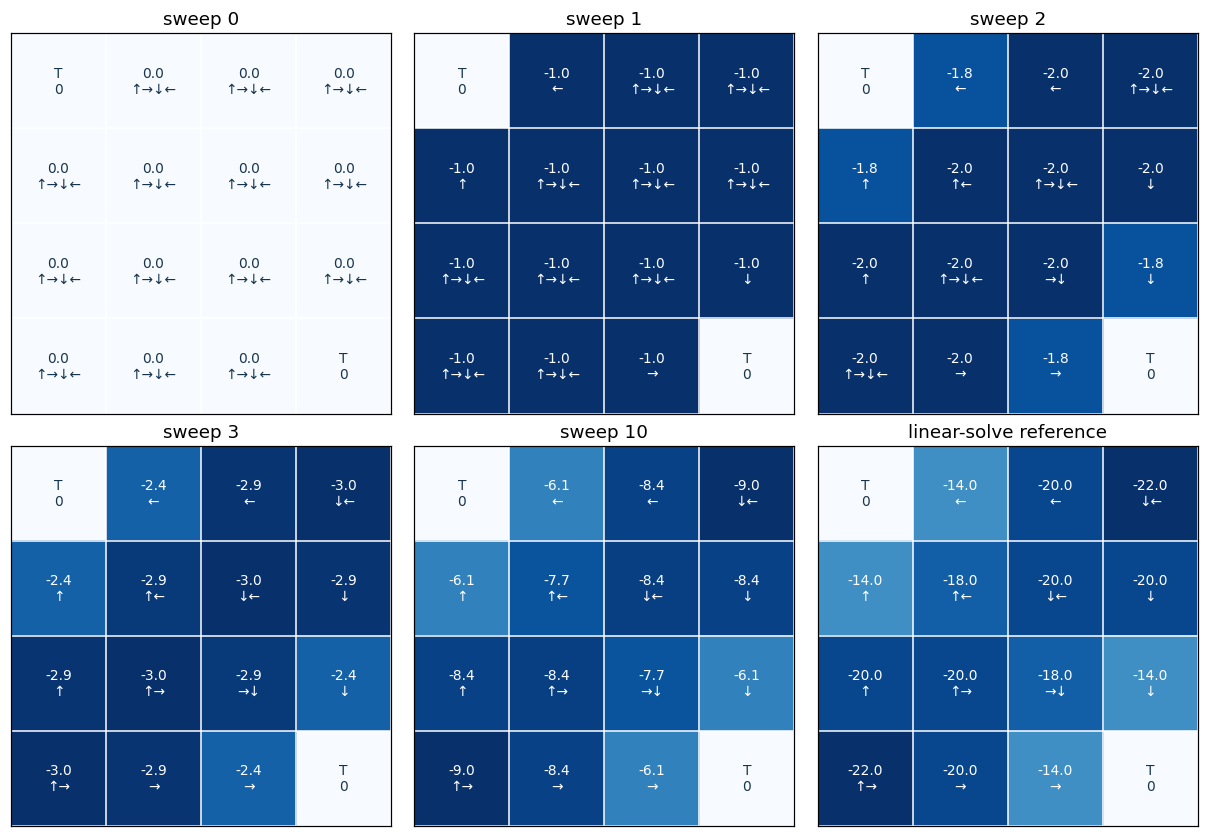

In [12]:
checkpoint_figure = new_figure(11.0, 7.5)
with Session(engine) as db:
    world = db.scalars(select(World).where(World.name == "main")).one()
    run = find_run(db, world, "random evaluation")
    for panel, requested in enumerate((0, 1, 2, 3, 10), start=1):
        sequence = min(requested, run.completed_sweeps)
        snapshot = db.scalars(select(Snapshot).where(
            Snapshot.run_id == run.id, Snapshot.sequence == sequence,
        )).one()
        greedify(db, run, snapshot)
        axis = checkpoint_figure.add_subplot(2, 3, panel)
        draw_snapshot(db, axis, snapshot, f"sweep {sequence}")
    reference_run = find_run(db, world, "random reference")
    reference = latest_snapshot(db, reference_run)
    greedify(db, reference_run, reference)
    draw_snapshot(db, checkpoint_figure.add_subplot(2, 3, 6), reference, "linear-solve reference")
    db.commit()
plt.show()  # pyright: ignore[reportUnknownMemberType]

4 × 4: 383 sweeps; error=1.820e-08


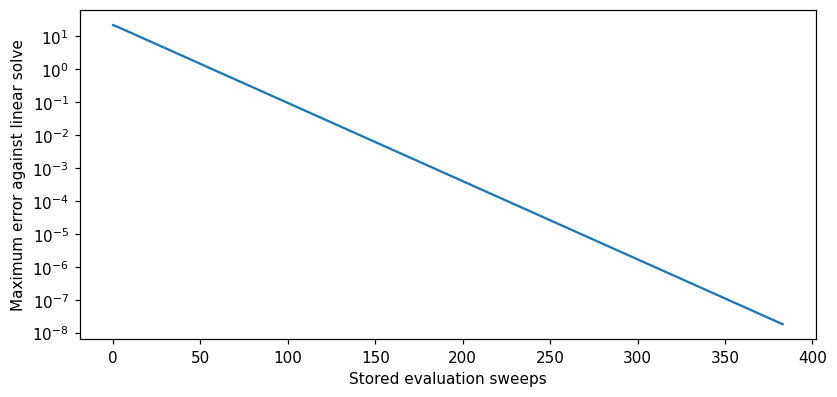

In [13]:
convergence_figure = new_figure(7.5, 3.5)
convergence_axis = convergence_figure.add_subplot(1, 1, 1)
with Session(engine) as db:
    world = db.scalars(select(World).where(World.name == "main")).one()
    run = find_run(db, world, "random evaluation")
    curve = error_query(db, run)
    convergence_axis.plot(  # pyright: ignore[reportUnknownMemberType]
        [x for x, _ in curve], [y for _, y in curve]
    )
    convergence_axis.set_yscale(  # pyright: ignore[reportUnknownMemberType]
        "symlog", linthresh=1e-10
    )
    convergence_axis.set_xlabel(  # pyright: ignore[reportUnknownMemberType]
        "Stored evaluation sweeps"
    )
    convergence_axis.set_ylabel(  # pyright: ignore[reportUnknownMemberType]
        "Maximum error against linear solve"
    )
    print(
        f"{world.height} × {world.width}: "
        f"{run.completed_sweeps} sweeps; error={curve[-1][1]:.3e}"
    )
plt.show()  # pyright: ignore[reportUnknownMemberType]

## 5. Improvement and policy iteration

The independent optimal-value reference comes from Manhattan distance to the configured terminal cells. This works for the open rectangular grids modeled here; walls or obstacles would require a different distance computation.

In [14]:
def distance_reference(db: Session, run: Run) -> Snapshot:
    snapshot = new_snapshot(db, run, "optimal_exact")
    terminal_cell = aliased(Cell)
    terminal_state = aliased(State)
    distance = (
        func.abs(Cell.row_index - terminal_cell.row_index)
        + func.abs(Cell.column_index - terminal_cell.column_index)
    )
    statement = (
        select(
            literal(run.world_id), literal(snapshot.id), Cell.state_id,
            -1.0 * func.min(distance),
        )
        .join(terminal_cell, terminal_cell.world_id == Cell.world_id)
        .join(terminal_state, terminal_state.id == terminal_cell.state_id)
        .where(Cell.world_id == run.world_id, terminal_state.is_terminal)
        .group_by(Cell.state_id)
    )
    db.execute(insert(StateValue).from_select(
        ["world_id", "snapshot_id", "state_id", "value"], statement,
    ))
    run.status = "converged"
    return finish_snapshot(db, run, snapshot)


def count_policy_changes(db: Session, old: Policy, new: Policy) -> int:
    previous = aliased(PolicyProbability)
    differences = (
        select(PolicyProbability.state_id)
        .join(previous, (
            (previous.state_id == PolicyProbability.state_id)
            & (previous.action_id == PolicyProbability.action_id)
        ))
        .where(PolicyProbability.policy_id == new.id, previous.policy_id == old.id)
        .where(func.abs(PolicyProbability.probability - previous.probability) > 1e-12)
        .group_by(PolicyProbability.state_id)
        .subquery()
    )
    return int(db.scalar(select(func.count()).select_from(differences)) or 0)


def policy_iteration(db: Session, run: Run) -> Snapshot:
    for iteration in range(1, run.max_iterations + 1):
        assert run.current_policy_id is not None
        policy = db.get(Policy, run.current_policy_id)
        assert policy is not None
        run.iterations = iteration
        snapshot = evaluate_exactly(db, run, policy)
        improved = greedify(db, run, snapshot)
        snapshot.changed_policy_states = count_policy_changes(db, policy, improved)
        run.current_policy_id = improved.id
        if snapshot.changed_policy_states == 0:
            assert snapshot.optimality_residual is not None
            if snapshot.optimality_residual > run.tolerance:
                raise RuntimeError("Policy is stable but its optimality residual is too large.")
            run.status = "converged"
            db.flush()
            return snapshot
    run.status = "failed"
    db.flush()
    raise RuntimeError("Policy iteration exceeded its stored iteration limit.")

In [15]:
with Session(engine) as db:
    world = db.scalars(select(World).where(World.name == "main")).one()
    random_run = find_run(db, world, "random reference")
    random_snapshot = latest_snapshot(db, random_run)
    improved_policy = greedify(db, random_run, random_snapshot)
    optimal_run = new_run(db, world, "optimal reference", "distance_reference")
    optimal_snapshot = distance_reference(db, optimal_run)
    improvement_run = new_run(
        db, world, "one improvement", "policy_improvement", improved_policy, optimal_snapshot,
    )
    improved_snapshot = evaluate_exactly(db, improvement_run, improved_policy)
    greedify(db, improvement_run, improved_snapshot)
    improvement_run.status = "converged"
    uniform = db.scalars(select(Policy).where(
        Policy.world_id == world.id, Policy.name == "uniform",
    )).one()
    iteration_run = new_run(
        db, world, "policy iteration", "policy_iteration", uniform, optimal_snapshot,
    )
    policy_iteration(db, iteration_run)
    db.commit()

**Look for:** how much one greedy improvement changes the random policy's values. The notebook evaluates the new policy before plotting it. Arrows show actions greedy with respect to each displayed value snapshot; they are not the random policy being evaluated on the left. The full policy-iteration run separately checks stability and the optimality residual; it does not assume one improvement is sufficient for every configuration.

Policy iteration: evaluated policies and changed state counts
0 14 13.000000000000002
1 2 0.0
2 0 0.0


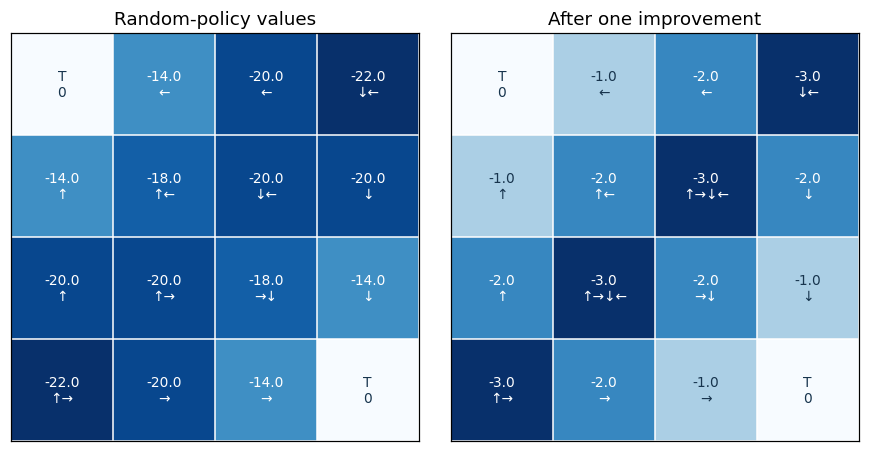

In [16]:
improvement_figure = new_figure(8.0, 4.0)
with Session(engine) as db:
    world = db.scalars(select(World).where(World.name == "main")).one()
    before = latest_snapshot(db, find_run(db, world, "random reference"))
    after = latest_snapshot(db, find_run(db, world, "one improvement"))
    draw_snapshot(db, improvement_figure.add_subplot(1, 2, 1), before, "Random-policy values")
    draw_snapshot(db, improvement_figure.add_subplot(1, 2, 2), after, "After one improvement")
    run = find_run(db, world, "policy iteration")
    print("Policy iteration: evaluated policies and changed state counts")
    for snapshot in db.scalars(select(Snapshot).where(Snapshot.run_id == run.id)
                              .order_by(Snapshot.sequence)):
        print(snapshot.sequence, snapshot.changed_policy_states, snapshot.optimality_residual)
plt.show()  # pyright: ignore[reportUnknownMemberType]